# 2. Survival with competing risks: default or prepayment

How likely is a mortgage to default within *t* months of its first payment? It sounds like a textbook Kaplan-Meier problem. It is not, because a loan can leave the portfolio in two ways.

In [1]:
import sys
sys.path.insert(0, "../src")
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from credit_risk.data import load_loans
from credit_risk.survival import cumulative_incidence, cif_at

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREY = "#1a73e8", "#d93025", "#80868b"

loans = load_loans((2006, 2017))
curves = {v: cumulative_incidence(g["time"], g["event"]) for v, g in loans.groupby("vintage")}

## Trap 2: treating prepayment as censoring doubles the default probability

Most loans do not default or run to maturity: they are **prepaid** when the borrower sells the house or refinances. The usual shortcut, "1 − Kaplan-Meier" with prepaid loans treated as censored, assumes that a prepaid loan *would have kept the same default risk as the loans still running*. But a refinanced loan cannot default at all. With competing risks, the right quantity is the **cumulative incidence function** (Aalen-Johansen estimator; formulas in `src/credit_risk/survival.py`).

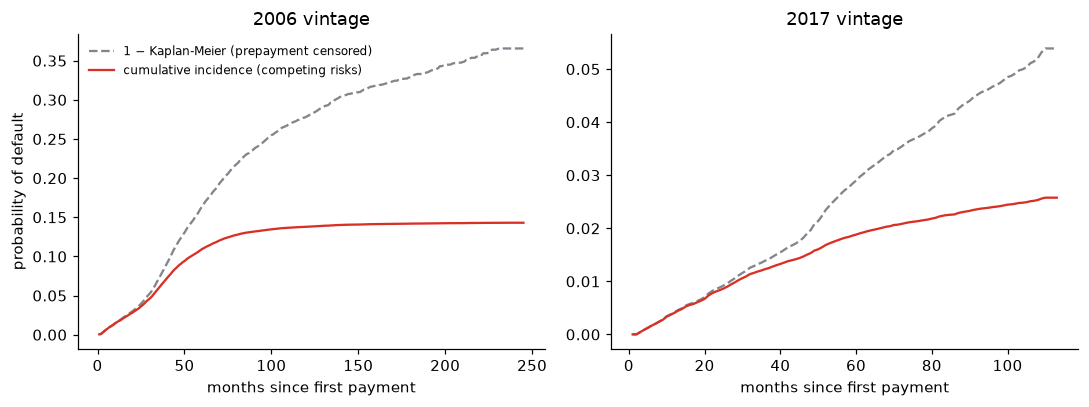

1 - KM (wrong)  cumulative incidence  overstatement
2006 36           0.0748                0.0618         1.2093
     60           0.1636                0.1092         1.4976
     100          0.2549                0.1347         1.8922
2017 36           0.0139                0.0123         1.1290
     60           0.0290                0.0188         1.5409
     100          0.0485                0.0245         1.9828

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=False)
for ax, (v, c) in zip(axes, curves.items()):
    ax.plot(c["month"], c["one_minus_km_default"], color=GREY, ls="--", label="1 − Kaplan-Meier (prepayment censored)")
    ax.plot(c["month"], c["cif_default"], color=RED, label="cumulative incidence (competing risks)")
    ax.set_title(f"{v} vintage")
    ax.set_xlabel("months since first payment")
axes[0].set_ylabel("probability of default")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("../figures/km_vs_cif.png", bbox_inches="tight")
plt.show()

compare = pd.DataFrame({
    (v, m): {"1 - KM (wrong)": c.set_index("month").loc[m, "one_minus_km_default"],
             "cumulative incidence": c.set_index("month").loc[m, "cif_default"]}
    for v, c in curves.items() for m in (36, 60, 100)
}).T
compare.assign(overstatement=compare.iloc[:, 0] / compare.iloc[:, 1])

The shortcut nearly **doubles** the long-run default probability. The error grows with time because more and more loans have been prepaid: in a mortgage book, prepayment is the main way loans leave.

*Check:* `lifelines.AalenJohansenFitter` gives the same curves to the second decimal place; the tiny differences come from how it breaks ties between causes in the same month (it adds random jitter), while the estimator here treats monthly data as discrete.

## Default and prepayment, side by side

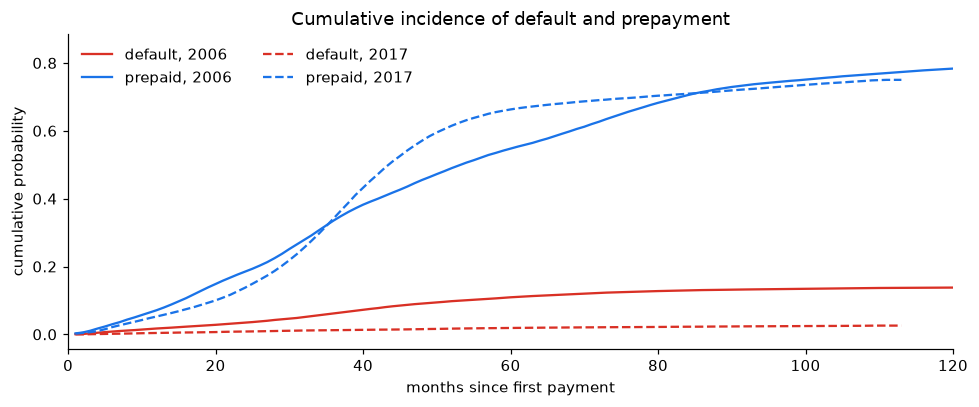

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for v, c in curves.items():
    style = "-" if v == 2006 else "--"
    ax.plot(c["month"], c["cif_default"], color=RED, ls=style, label=f"default, {v}")
    ax.plot(c["month"], c["cif_prepay"], color=BLUE, ls=style, label=f"prepaid, {v}")
ax.set_xlabel("months since first payment")
ax.set_ylabel("cumulative probability")
ax.set_xlim(0, 120)
ax.legend(frameon=False, ncol=2)
ax.set_title("Cumulative incidence of default and prepayment")
fig.tight_layout()
fig.savefig("../figures/cif_default_prepay.png", bbox_inches="tight")
plt.show()

Two different stories:

- **2006** loans started defaulting about two years after origination, just when house prices collapsed, and kept defaulting for years.
- **2017** loans were mostly **refinanced in 2020–2021**, when rates fell to record lows: the steep prepayment curve. A refinanced loan leaves the portfolio before it can default, which is part of why 2017 looks so safe.

## Does the credit score explain the difference?

Compare borrowers *with the same credit score* across vintages:

In [4]:
bands = pd.cut(loans["fico"], [300, 660, 720, 760, 851], right=False,
               labels=["< 660", "660–719", "720–759", "760+"])
by_band = cif_at(loans.assign(fico_band=bands).dropna(subset=["fico_band"]), months=(36, 60), by=["vintage", "fico_band"])
table = by_band["60 months"].unstack("vintage").reindex(["< 660", "660–719", "720–759", "760+"])
table["ratio 2006 / 2017"] = table[2006] / table[2017]
table.join(by_band["loans"].unstack("vintage").add_prefix("loans "))

vintage,2006,2017,ratio 2006 / 2017,loans 2006,loans 2017
fico_band,,,,,
< 660,0.2411,0.0756,3.1890,7687,2537
660–719,0.1449,0.0327,4.4367,14794,12384
720–759,0.0830,0.0153,5.4396,10849,12794
760+,0.0338,0.0067,5.0209,16624,22277


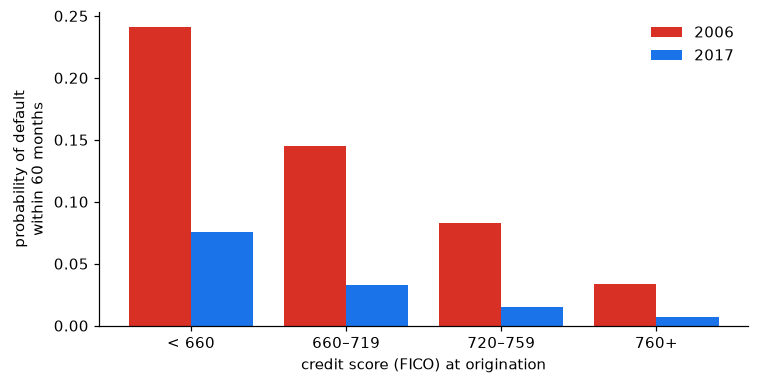

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(table))
ax.bar(x - 0.2, table[2006], width=0.4, color=RED, label="2006")
ax.bar(x + 0.2, table[2017], width=0.4, color=BLUE, label="2017")
ax.set_xticks(x, table.index)
ax.set_xlabel("credit score (FICO) at origination")
ax.set_ylabel("probability of default\nwithin 60 months")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("../figures/default_by_fico.png", bbox_inches="tight")
plt.show()

Within every credit-score band, 2006 loans defaulted several times more often than 2017 loans. The score ranks borrowers well inside a vintage, but the *level* of risk depends on something the score does not see: the economy the loan lived through. Notebook 3 measures this with a model that adjusts for all borrower characteristics at once.

In [6]:
pd.concat({v: c.set_index("month")[["cif_default", "cif_prepay", "one_minus_km_default"]] for v, c in curves.items()},
          names=["vintage"]).to_csv("../results/cumulative_incidence.csv")
by_band.to_csv("../results/default_by_fico_band.csv")